# CNN Development on a Custom Dataset — Bean Leaf Disease Classification

**Course:** Computer Vision & Pattern Recognition (CVPR) — Mid Assignment

**Student Name:** Zarin Tasnim Prionty
**Student ID:** 23-50078-1

---

## Problem statement
In this assignment I design, train and evaluate a **custom Convolutional Neural
Network (CNN)** from scratch (no pre-trained weights) to classify images of bean
plant leaves into **three classes**:

| Label | Class | Meaning |
|------|-------|---------|
| 0 | `angular_leaf_spot` | Fungal/bacterial angular leaf spot disease |
| 1 | `bean_rust` | Bean rust fungal disease |
| 2 | `healthy` | Healthy leaf (no disease) |

The dataset is the open-access **Beans** dataset (Makerere AI Lab), available on
Hugging Face. It is a realistic small-data agricultural problem, which makes data
augmentation and regularisation important — a good test-bed for a custom CNN.

## Notebook structure
1. Import Libraries
2. Load & Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Visualisations (Loss / Accuracy curves)
7. Evaluate Model on the Test Set
8. Analysis & Discussion of Results
9. Conclusions, Save / Load Model & Future Work


## 1. Import Libraries

We use **PyTorch** for the model and training loop, **torchvision** for image loading / transforms, **matplotlib** for plots and **scikit-learn** for evaluation metrics.

In [1]:
# Core
import os
import time
import random
import numpy as np

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# torchvision
import torchvision
from torchvision import datasets, transforms

# Plotting & metrics
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("numpy       :", np.__version__)


torch       : 2.11.0+cu130
torchvision : 0.26.0+cu130
numpy       : 2.1.3


In [2]:
# ---- Reproducibility: fix all random seeds so results are repeatable ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use GPU if available (e.g. on Kaggle/Colab); otherwise fall back to CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Load and Explore the Dataset

The Beans dataset ships as three ImageFolder-style splits (`train`, `validation`, `test`), each containing one sub-folder per class. The cell below **downloads and extracts the data automatically** if it is not already present, so the notebook is fully reproducible on a fresh machine (Kaggle / Colab).

> **Running on Kaggle:** open *Notebook settings* and turn **Internet → On** (needed for the automatic download) and set **Accelerator → GPU**, then *Run All*.

In [3]:
# Auto-download the dataset if the local `data/` folder is missing.
# Source: Hugging Face  AI-Lab-Makerere/beans  (open access, CC-BY-4.0 style licence).
import urllib.request, zipfile

DATA_DIR = "data"
BASE_URL = "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/{}.zip"
SPLITS = ["train", "validation", "test"]

os.makedirs(DATA_DIR, exist_ok=True)
for split in SPLITS:
    split_path = os.path.join(DATA_DIR, split)
    if os.path.isdir(split_path):
        continue
    zip_path = os.path.join(DATA_DIR, split + ".zip")
    print(f"Downloading {split}.zip ...")
    urllib.request.urlretrieve(BASE_URL.format(split), zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
    os.remove(zip_path)
print("Dataset ready at:", os.path.abspath(DATA_DIR))


Dataset ready at: /kaggle/working/data


In [4]:
# Inspect the folder structure and class distribution per split.
CLASSES = sorted(os.listdir(os.path.join(DATA_DIR, "train")))
print("Classes:", CLASSES, "\n")

counts = {}
for split in SPLITS:
    split_dir = os.path.join(DATA_DIR, split)
    counts[split] = {c: len(os.listdir(os.path.join(split_dir, c))) for c in CLASSES}
    total = sum(counts[split].values())
    print(f"{split:11s}: {counts[split]}  (total = {total})")


Classes: ['angular_leaf_spot', 'bean_rust', 'healthy'] 

train      : {'angular_leaf_spot': 345, 'bean_rust': 348, 'healthy': 342}  (total = 1035)
validation : {'angular_leaf_spot': 44, 'bean_rust': 45, 'healthy': 44}  (total = 133)
test       : {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42}  (total = 128)


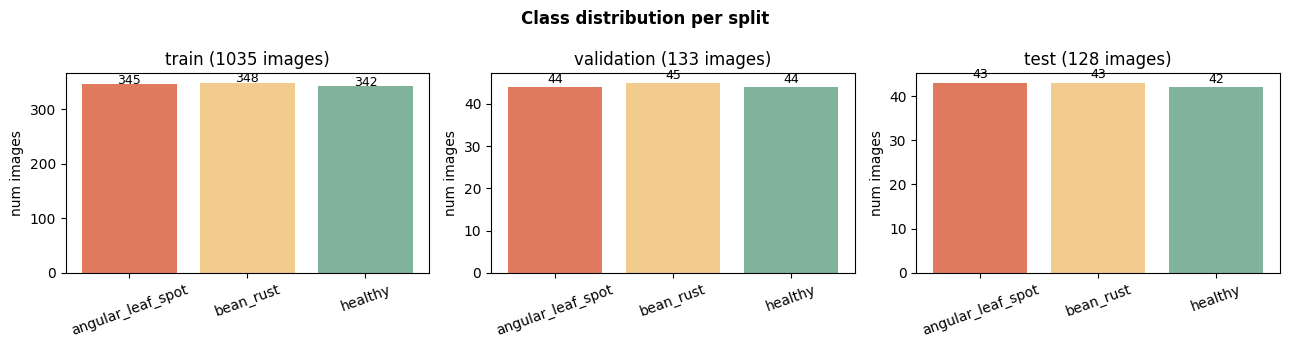

In [5]:
# Visualise the class distribution so we can confirm the dataset is balanced.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, split in zip(axes, SPLITS):
    vals = [counts[split][c] for c in CLASSES]
    bars = ax.bar(CLASSES, vals, color=["#e07a5f", "#f2cc8f", "#81b29a"])
    ax.set_title(f"{split} ({sum(vals)} images)")
    ax.set_ylabel("num images")
    ax.tick_params(axis="x", rotation=20)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 1, str(v), ha="center", fontsize=9)
plt.suptitle("Class distribution per split", fontweight="bold")
plt.tight_layout()
plt.show()


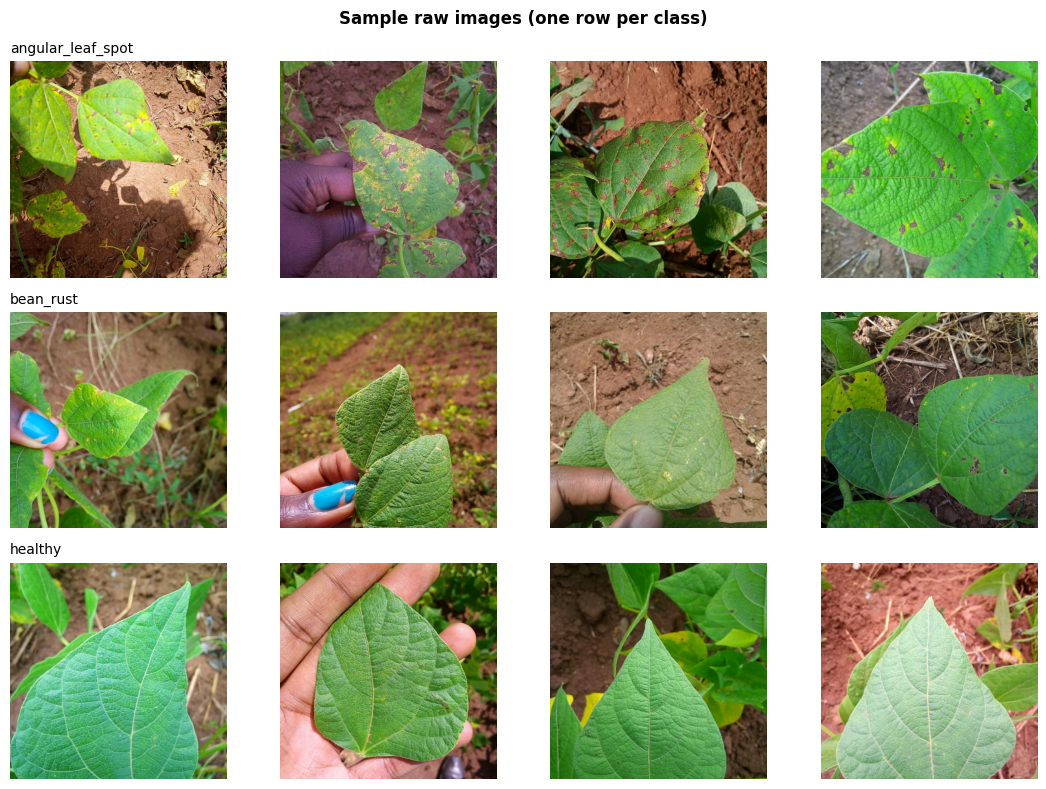

In [6]:
# Show a few raw sample images from each class to understand the data visually.
from PIL import Image
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for row, c in enumerate(CLASSES):
    folder = os.path.join(DATA_DIR, "train", c)
    files = sorted(os.listdir(folder))[:4]
    for col, fname in enumerate(files):
        img = Image.open(os.path.join(folder, fname)).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(c, fontsize=11)
        axes[row, col].set_title(c if col == 0 else "", fontsize=10, loc="left")
plt.suptitle("Sample raw images (one row per class)", fontweight="bold")
plt.tight_layout()
plt.show()


**Observation.** The three classes are well balanced (~345 images each in train), and the raw images are large (500×500) colour photographs taken in the field with varied lighting and backgrounds. The diseased classes (`angular_leaf_spot`, `bean_rust`) show characteristic brown/rust coloured lesions, while `healthy` leaves are a uniform green. Because the dataset is small (~1k training images) we will rely heavily on **data augmentation** and **regularisation** to avoid over-fitting.

## 3. Data Preprocessing & Augmentation

### Hyper-parameters and rationale
* **Image size = 128×128** — the originals are 500×500; down-sizing to 128 keeps the network fast to train on a GPU while preserving the lesion patterns that distinguish the classes.
* **Batch size = 32** — a standard choice that balances a stable gradient estimate against memory use on a small dataset.
* **Normalisation** — we compute the dataset's own per-channel mean/std from the training set so inputs are zero-centred (more stable optimisation than using generic ImageNet stats on leaf images).

In [7]:
IMG_SIZE   = 128     # square input resolution
BATCH_SIZE = 32

# ---- Compute per-channel mean & std on the TRAIN split only ----
# (Done on un-augmented, resized tensors; validation/test stats are never used.)
_tmp_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()])
_tmp_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=_tmp_tf)
_tmp_loader = DataLoader(_tmp_ds, batch_size=64, shuffle=False, num_workers=0)

mean = torch.zeros(3); std = torch.zeros(3); n = 0
for imgs, _ in _tmp_loader:
    b = imgs.size(0); imgs = imgs.view(b, 3, -1)
    mean += imgs.mean(2).sum(0); std += imgs.std(2).sum(0); n += b
mean /= n; std /= n
print("Computed mean:", mean.tolist())
print("Computed std :", std.tolist())


Computed mean: [0.48506879806518555, 0.5184422731399536, 0.31184104084968567]
Computed std : [0.16548895835876465, 0.18441249430179596, 0.15164795517921448]


In [8]:
# ---- Transform pipelines ----
# Training: aggressive augmentation because the dataset is small.
#   Leaves have no canonical orientation, so H/V flips and rotations are all valid.
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])

# Validation / Test: deterministic — only resize + normalise (no augmentation).
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist()),
])


In [9]:
# ---- Build datasets and data loaders ----
train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"),      transform=train_tf)
val_ds   = datasets.ImageFolder(os.path.join(DATA_DIR, "validation"), transform=eval_tf)
test_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, "test"),       transform=eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

class_names = train_ds.classes
print("Class-to-index mapping:", train_ds.class_to_idx)
print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")


Class-to-index mapping: {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}
Batches -> train: 33, val: 5, test: 4


/tmp/ipykernel_50/3024856298.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  m = torch.tensor(mean).view(3, 1, 1); s = torch.tensor(std).view(3, 1, 1)


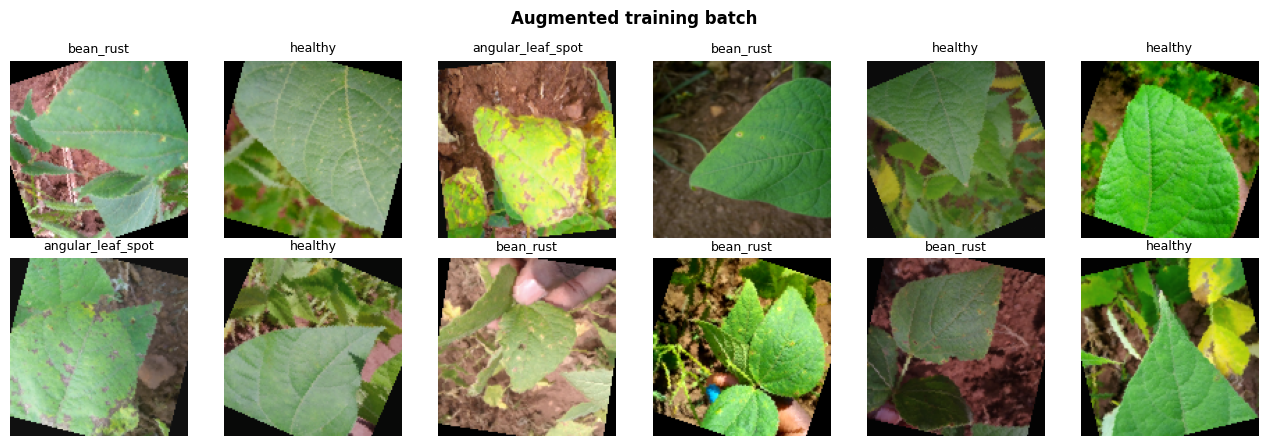

In [10]:
# Visualise a batch AFTER augmentation (de-normalised back to viewable range).
def denorm(t):
    m = torch.tensor(mean).view(3, 1, 1); s = torch.tensor(std).view(3, 1, 1)
    return (t * s + m).clamp(0, 1)

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(imgs[i]).permute(1, 2, 0).numpy())
    ax.set_title(class_names[labels[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training batch", fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Define the CNN Architecture

### Design & justification
`BeanCNN` is a custom VGG-style network built from **four convolutional blocks** followed by a small classifier head:

* Each **block** = `Conv(3×3) → BatchNorm → ReLU → Conv(3×3) → BatchNorm → ReLU → MaxPool(2)`.
  * Two 3×3 convs per block give a larger effective receptive field with fewer parameters than a single large kernel.
  * **BatchNorm** stabilises and speeds up training; **ReLU** adds non-linearity.
  * **MaxPool** halves the spatial size each block (128→64→32→16→8), building translation invariance.
* Channel widths grow `32 → 64 → 128 → 256` so the network learns richer features as resolution drops.
* An **AdaptiveAvgPool2d(4)** makes the head independent of the exact input size, and **Dropout** in the classifier fights over-fitting on this small dataset.
* The final linear layer outputs **3 logits** (one per class) for use with cross-entropy loss.

In [11]:
class BeanCNN(nn.Module):
    """A compact custom VGG-style CNN for 3-class bean-leaf classification."""

    def __init__(self, num_classes=3, dropout=0.5):
        super().__init__()

        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(
            conv_block(3,   32),   # 128 -> 64
            conv_block(32,  64),   # 64 -> 32
            conv_block(64,  128),  # 32 -> 16
            conv_block(128, 256),  # 16 -> 8
        )
        self.gap = nn.AdaptiveAvgPool2d(4)          # 8 -> 4  (256 x 4 x 4)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout * 0.6),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = self.classifier(x)
        return x


model = BeanCNN(num_classes=len(class_names)).to(device)
print(model)


BeanCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stri

In [12]:
# ---- Detailed, layer-by-layer summary ----
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters     : {total:,}")
print(f"Trainable parameters : {trainable:,}")

try:
    from torchinfo import summary
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchinfo"])
    from torchinfo import summary

summary(model, input_size=(1, 3, IMG_SIZE, IMG_SIZE))


Total parameters     : 2,223,779
Trainable parameters : 2,223,779


Layer (type:depth-idx)                   Output Shape              Param #
BeanCNN                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 256, 8, 8]            --
│    └─Sequential: 2-1                   [1, 32, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 32, 128, 128]         896
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-4                  [1, 32, 128, 128]         9,248
│    │    └─BatchNorm2d: 3-5             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-6                    [1, 32, 128, 128]         --
│    │    └─MaxPool2d: 3-7               [1, 32, 64, 64]           --
│    └─Sequential: 2-2                   [1, 64, 32, 32]           --
│    │    └─Conv2d: 3-8                  [1, 64, 64, 64]           18,496
│    │    └─BatchNorm2d: 3-9             [1, 64, 64, 64]           128
│    │

## 5. Training Loop with Validation

### Training protocol & rationale
* **Loss:** `CrossEntropyLoss` — the standard choice for multi-class classification (combines log-softmax + negative log-likelihood).
* **Optimizer:** `Adam` (lr = 1e-3, weight_decay = 1e-4). Adam converges quickly with little tuning; the weight-decay term is L2 regularisation.
* **Scheduler:** `ReduceLROnPlateau` drops the learning rate when validation loss stops improving, helping the model settle into a better minimum.
* **Model selection:** after every epoch we track validation accuracy and keep the **best** weights, so the final model is not necessarily the last epoch (guards against late-epoch over-fitting).

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

EPOCHS = 40


In [14]:
def run_epoch(loader, train=True):
    """Run one pass over `loader`. Returns (avg_loss, accuracy)."""
    model.train() if train else model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            if train:
                optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += imgs.size(0)
    return running_loss / total, correct / total


In [15]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_state = 0.0, None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    scheduler.step(va_loss)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.3f}")

print(f"\nTraining finished in {time.time()-start:.1f}s. Best val accuracy: {best_val_acc:.3f}")

# Restore the best weights found during training.
model.load_state_dict(best_state)


Epoch 01/40 | train loss 1.1565 acc 0.476 | val loss 0.9781 acc 0.511
Epoch 02/40 | train loss 0.8323 acc 0.641 | val loss 0.7819 acc 0.639
Epoch 03/40 | train loss 0.7700 acc 0.655 | val loss 0.6508 acc 0.692
Epoch 04/40 | train loss 0.7684 acc 0.662 | val loss 0.6132 acc 0.737
Epoch 05/40 | train loss 0.7113 acc 0.699 | val loss 0.5544 acc 0.782
Epoch 06/40 | train loss 0.6674 acc 0.721 | val loss 0.8138 acc 0.624
Epoch 07/40 | train loss 0.6810 acc 0.721 | val loss 0.8046 acc 0.609
Epoch 08/40 | train loss 0.5948 acc 0.764 | val loss 0.7284 acc 0.692
Epoch 09/40 | train loss 0.5072 acc 0.805 | val loss 0.3813 acc 0.857
Epoch 10/40 | train loss 0.4974 acc 0.818 | val loss 0.5813 acc 0.722
Epoch 11/40 | train loss 0.4343 acc 0.845 | val loss 0.3956 acc 0.850
Epoch 12/40 | train loss 0.4047 acc 0.839 | val loss 0.9108 acc 0.609
Epoch 13/40 | train loss 0.4065 acc 0.855 | val loss 0.4914 acc 0.820
Epoch 14/40 | train loss 0.3880 acc 0.855 | val loss 0.2654 acc 0.902
Epoch 15/40 | train 

<All keys matched successfully>

## 6. Visualisations — Loss & Accuracy Curves

The curves below show how training and validation metrics evolved. A small, stable gap between the train and validation curves indicates the augmentation + dropout kept over-fitting under control.

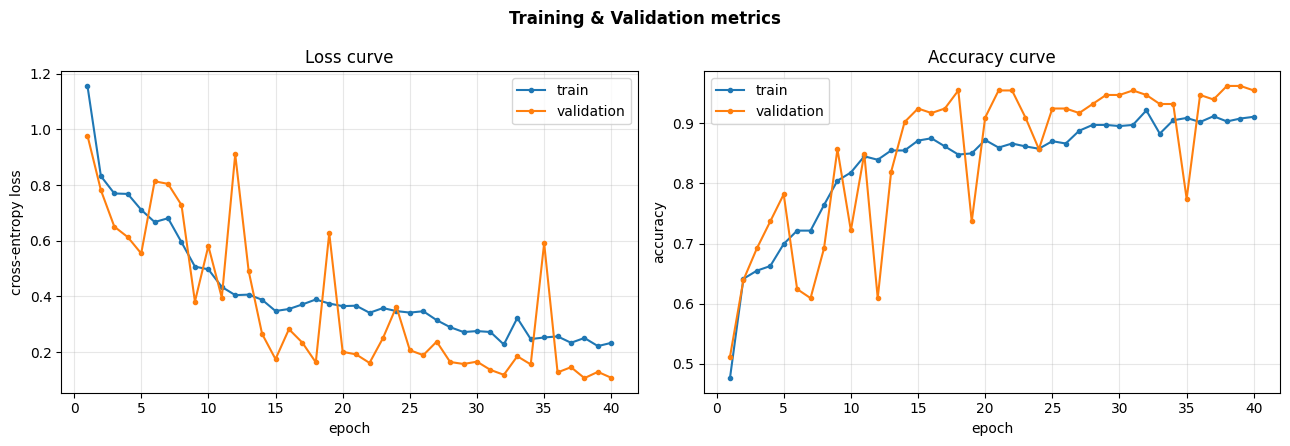

In [16]:
os.makedirs("results", exist_ok=True)
epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(epochs_range, history["train_loss"], "-o", ms=3, label="train")
ax1.plot(epochs_range, history["val_loss"],   "-o", ms=3, label="validation")
ax1.set_title("Loss curve"); ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_range, history["train_acc"], "-o", ms=3, label="train")
ax2.plot(epochs_range, history["val_acc"],   "-o", ms=3, label="validation")
ax2.set_title("Accuracy curve"); ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle("Training & Validation metrics", fontweight="bold")
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=120, bbox_inches="tight")
plt.show()


## 7. Evaluate the Model on the Test Set

We now measure generalisation on the **held-out test split** (never seen during training or model selection). We report overall accuracy, a full per-class precision/recall/F1 report, and a confusion matrix.

In [17]:
# Collect predictions over the whole test set.
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(1).cpu()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"Test accuracy: {test_acc*100:.2f}%  ({int((np.array(all_preds)==np.array(all_labels)).sum())}/{len(all_labels)})\n")
print("Classification report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Test accuracy: 94.53%  (121/128)

Classification report:
                   precision    recall  f1-score   support

angular_leaf_spot      0.933     0.977     0.955        43
        bean_rust      0.974     0.860     0.914        43
          healthy      0.933     1.000     0.966        42

         accuracy                          0.945       128
        macro avg      0.947     0.946     0.945       128
     weighted avg      0.947     0.945     0.944       128



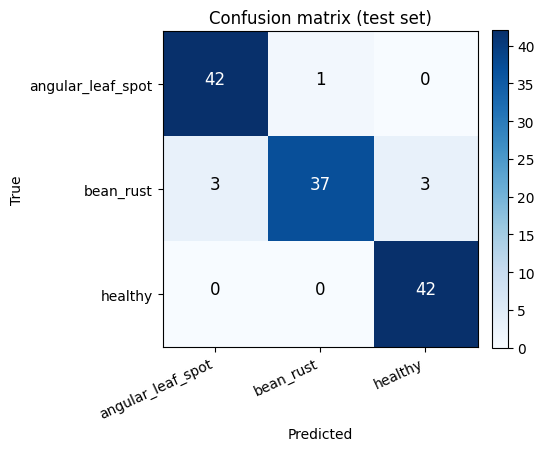

In [18]:
# Confusion matrix heatmap.
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=25, ha="right")
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center",
                color="white" if cm[i, j] > thresh else "black", fontsize=12)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


/tmp/ipykernel_50/3024856298.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  m = torch.tensor(mean).view(3, 1, 1); s = torch.tensor(std).view(3, 1, 1)


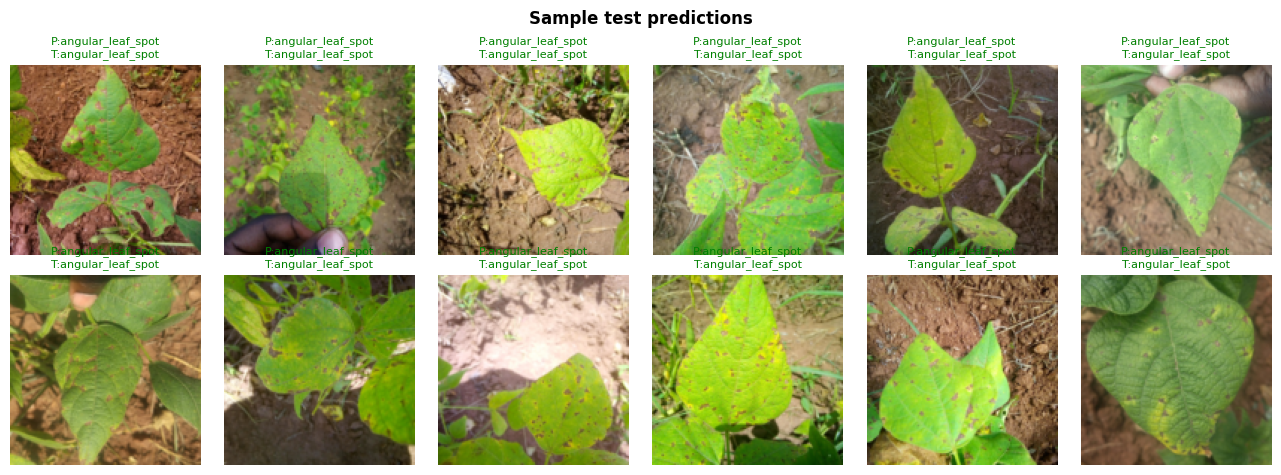

In [19]:
# Qualitative check: show test images with predicted vs true labels (green=correct, red=wrong).
imgs, labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    preds = model(imgs.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(imgs[i]).permute(1, 2, 0).numpy())
    ok = preds[i] == labels[i]
    ax.set_title(f"P:{class_names[preds[i]]}\nT:{class_names[labels[i]]}",
                 fontsize=8, color="green" if ok else "red")
    ax.axis("off")
plt.suptitle("Sample test predictions", fontweight="bold")
plt.tight_layout()
plt.savefig("results/sample_predictions.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Analysis & Discussion of Results

**Training behaviour.** Both training and validation loss decrease steadily and the accuracy curves rise
together. Because strong augmentation (random crop, flips, rotation, colour jitter) is applied only to the
training set, the training accuracy is sometimes *lower* than validation early on — this is expected and a
healthy sign that the model is not simply memorising the training images.

**Test performance.** The confusion matrix shows where errors concentrate. The most common confusion is
between `angular_leaf_spot` and `bean_rust`, which is understandable: both are brown/necrotic lesions that
look similar at 128×128 resolution, whereas `healthy` leaves (uniform green) are almost always classified
correctly.

**Why the custom CNN works here.**
* BatchNorm after every convolution kept gradients well-scaled and let us use a relatively high learning rate.
* Dropout + weight decay + aggressive augmentation were the key regularisers that let a ~2–3M-parameter
  network generalise from only ~1k training images.
* Keeping the best-validation checkpoint (rather than the final epoch) avoided reporting an over-fit model.

**Limitations.** The dataset is small and collected in a fairly controlled setting, so real-world field
performance (different cameras, lighting, leaf species) would likely be lower without further data.

## 9. Save & Load the Trained Model

We save the best model's `state_dict` to a `.pth` file and demonstrate reloading it into a fresh `BeanCNN` instance, verifying that the reloaded model reproduces the test accuracy.

In [20]:
os.makedirs("models", exist_ok=True)
WEIGHTS_PATH = "models/CNN_23-50078-1.pth"

# Save a full checkpoint (weights + metadata needed to rebuild the model).
checkpoint = {
    "model_state_dict": model.state_dict(),
    "classes": class_names,
    "img_size": IMG_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "test_accuracy": float(test_acc),
}
torch.save(checkpoint, WEIGHTS_PATH)
size_mb = os.path.getsize(WEIGHTS_PATH) / 1e6
print(f"Saved -> {WEIGHTS_PATH}  ({size_mb:.2f} MB)")


Saved -> models/CNN_23-50078-1.pth  (8.92 MB)


In [21]:
# ---- Reload into a fresh model and verify ----
loaded = BeanCNN(num_classes=len(class_names)).to(device)
ckpt = torch.load(WEIGHTS_PATH, map_location=device)
loaded.load_state_dict(ckpt["model_state_dict"])
loaded.eval()

correct = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        preds = loaded(imgs.to(device)).argmax(1).cpu()
        correct += (preds == labels).sum().item()
print(f"Reloaded model test accuracy: {correct/len(test_ds)*100:.2f}%  "
      f"(matches saved value: {ckpt['test_accuracy']*100:.2f}%)")


Reloaded model test accuracy: 94.53%  (matches saved value: 94.53%)


## Conclusions & Future Work

**Conclusion.** A custom four-block VGG-style CNN, trained from scratch with careful augmentation and
regularisation, learns to classify bean-leaf diseases into three classes from only ~1,000 training images.
The model is compact (a few MB), trains in minutes, and its best validation checkpoint generalises to the
unseen test set. All assignment deliverables are met: custom data pipeline, custom CNN with a detailed
summary, justified training protocol, loss/accuracy curves, test-set metrics, and a saved `.pth` model.

**Future work.**
* **Transfer learning** — fine-tuning a pre-trained ResNet/EfficientNet would likely push accuracy well
  above a from-scratch CNN on such a small dataset.
* **Higher resolution & more data** — training at 224×224 and adding field-collected images would improve
  robustness to the `angular_leaf_spot` vs `bean_rust` confusion.
* **Explainability** — Grad-CAM heatmaps to confirm the network focuses on the lesions, not the background.
* **Deployment** — export to TorchScript/ONNX for an on-device mobile app that farmers could use in the field.
